<a href="https://colab.research.google.com/github/janamh4/Room-Occupancy-Detection/blob/main/Room_Occupancy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [ ]:

import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/357/occupancy+detection.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print(z.namelist())


['datatest.txt', 'datatest2.txt', 'datatraining.txt']


In [ ]:

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    train_df = pd.read_csv(z.open("datatraining.txt"), index_col=0)
    test1_df = pd.read_csv(z.open("datatest.txt"), index_col=0)
    test2_df = pd.read_csv(z.open("datatest2.txt"), index_col=0)

print("Training:", train_df.shape)
print("Test 1:", test1_df.shape)
print("Test 2:", test2_df.shape)

train_df.head()


Training: (8143, 7)
Test 1: (2665, 7)
Test 2: (9752, 7)


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [ ]:

for name, df in [
    ("Training", train_df),
    ("Test 1", test1_df),
    ("Test 2", test2_df)
]:
    print("\n", name)
    print("Missing Values:", df.isnull().sum().sum())
    print("Duplicates:", df.duplicated().sum())
    print("Data Types:")
    print(df.dtypes)



 Training
Missing Values: 0
Duplicates: 0
Data Types:
date              object
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

 Test 1
Missing Values: 0
Duplicates: 0
Data Types:
date              object
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

 Test 2
Missing Values: 0
Duplicates: 0
Data Types:
date              object
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object


In [ ]:

for name, df in [
    ("Training", train_df),
    ("Test 1", test1_df),
    ("Test 2", test2_df)
]:
    print("\n", name)
    print(df["Occupancy"].value_counts())
    print("Percentages:")
    print(df["Occupancy"].value_counts(normalize=True) * 100)



 Training
Occupancy
0    6414
1    1729
Name: count, dtype: int64
Percentages:
Occupancy
0    78.767039
1    21.232961
Name: proportion, dtype: float64

 Test 1
Occupancy
0    1693
1     972
Name: count, dtype: int64
Percentages:
Occupancy
0    63.527205
1    36.472795
Name: proportion, dtype: float64

 Test 2
Occupancy
0    7703
1    2049
Name: count, dtype: int64
Percentages:
Occupancy
0    78.988925
1    21.011075
Name: proportion, dtype: float64


In [ ]:

train_df["date"] = pd.to_datetime(train_df["date"])

train_df = train_df.sort_values("date").reset_index(drop=True)

print("First date:", train_df["date"].min())
print("Last date:", train_df["date"].max())
print("Training rows:", len(train_df))

train_df.head()


First date: 2015-02-04 17:51:00
Last date: 2015-02-10 09:33:00
Training rows: 8143


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [ ]:

split_index = int(len(train_df) * 0.8)

train_data = train_df.iloc[:split_index].copy()
val_data = train_df.iloc[split_index:].copy()

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Test 1:", test1_df.shape)
print("Test 2:", test2_df.shape)


Training: (6514, 7)
Validation: (1629, 7)
Test 1: (2665, 7)
Test 2: (9752, 7)


In [ ]:

print("Training Distribution:")
print(train_data["Occupancy"].value_counts())
print(train_data["Occupancy"].value_counts(normalize=True) * 100)

print("\nValidation Distribution:")
print(val_data["Occupancy"].value_counts())
print(val_data["Occupancy"].value_counts(normalize=True) * 100)


Training Distribution:
Occupancy
0    5373
1    1141
Name: count, dtype: int64
Occupancy
0    82.483881
1    17.516119
Name: proportion, dtype: float64

Validation Distribution:
Occupancy
0    1041
1     588
Name: count, dtype: int64
Occupancy
0    63.904236
1    36.095764
Name: proportion, dtype: float64


In [ ]:

features = [
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio"
]

target = "Occupancy"

X_train = train_data[features]
y_train = train_data[target]

X_val = val_data[features]
y_val = val_data[target]

X_test1 = test1_df[features]
y_test1 = test1_df[target]

X_test2 = test2_df[features]
y_test2 = test2_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


X_train: (6514, 5)
y_train: (6514,)
X_val: (1629, 5)
y_val: (1629,)


In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test1_scaled = scaler.transform(X_test1)
X_test2_scaled = scaler.transform(X_test2)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test 1:", X_test1_scaled.shape)
print("Test 2:", X_test2_scaled.shape)

print("Training means:", X_train_scaled.mean(axis=0).round(3))


Training: (6514, 5)
Validation: (1629, 5)
Test 1: (2665, 5)
Test 2: (9752, 5)
Training means: [-0.  0.  0.  0.  0.]


In [ ]:

import numpy as np
import joblib

np.savez_compressed(
    "prepared_data.npz",
    X_train=X_train_scaled,
    y_train=y_train.to_numpy(),
    X_val=X_val_scaled,
    y_val=y_val.to_numpy(),
    X_test1=X_test1_scaled,
    y_test1=y_test1.to_numpy(),
    X_test2=X_test2_scaled,
    y_test2=y_test2.to_numpy()
)

joblib.dump(scaler, "scaler.joblib")

print("Prepared data saved successfully!")
print("Scaler saved successfully!")


Prepared data saved successfully!
Scaler saved successfully!


In [ ]:

np.savez_compressed(
    "raw_data.npz",
    X_train_raw=X_train.to_numpy(),
    X_val_raw=X_val.to_numpy(),
    X_test1_raw=X_test1.to_numpy(),
    X_test2_raw=X_test2.to_numpy()
)

print("Raw data saved successfully!")


Raw data saved successfully!


In [ ]:

import os

files_to_check = [
    "prepared_data.npz",
    "raw_data.npz",
    "scaler.joblib"
]

for file in files_to_check:
    if os.path.exists(file):
        print(file, "Found")
    else:
        print(file, "Missing")


prepared_data.npz Found
raw_data.npz Found
scaler.joblib Found


In [ ]:

import json

metadata = {
    "dataset": "UCI Occupancy Detection",
    "random_seed": SEED,
    "features": features,
    "target": target,
    "split_method": "Chronological 80/20 split of original training data",
    "training_samples": len(train_data),
    "validation_samples": len(val_data),
    "test1_samples": len(test1_df),
    "test2_samples": len(test2_df),
    "scaling": "StandardScaler fitted on training data only",
    "missing_values": 0,
    "duplicates": 0
}

with open("metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")


Metadata saved successfully!


In [ ]:
import numpy as np
import joblib

prepared = np.load("prepared_data.npz")

X_train = prepared["X_train"]
y_train = prepared["y_train"]

X_val = prepared["X_val"]
y_val = prepared["y_val"]

X_test1 = prepared["X_test1"]
y_test1 = prepared["y_test1"]

X_test2 = prepared["X_test2"]
y_test2 = prepared["y_test2"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test 1:", X_test1.shape, y_test1.shape)
print("Test 2:", X_test2.shape, y_test2.shape)

Training: (6514, 5) (6514,)
Validation: (1629, 5) (1629,)
Test 1: (2665, 5) (2665,)
Test 2: (9752, 5) (9752,)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
tf.random.set_seed(42)

In [ ]:
mlp_model = keras.Sequential([
    layers.Input(shape=(5,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
mlp_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = mlp_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9741 - loss: 0.1625 - val_accuracy: 0.9515 - val_loss: 0.1788
Epoch 2/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9870 - loss: 0.0458 - val_accuracy: 0.9533 - val_loss: 0.2039
Epoch 3/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9870 - loss: 0.0432 - val_accuracy: 0.9527 - val_loss: 0.2136
Epoch 4/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9870 - loss: 0.0417 - val_accuracy: 0.9521 - val_loss: 0.2162
Epoch 5/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9870 - loss: 0.0404 - val_accuracy: 0.9527 - val_loss: 0.2172
Epoch 6/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9870 - loss: 0.0392 - val_accuracy: 0.9527 - val_loss: 0.2166
Epoch 7/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9870 - loss: 0.0378 - val_accuracy: 0.9527 - val_loss: 0.2169
Epoch 8/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9870 - loss: 0.0363 - val_accuracy: 0.

In [ ]:
y_val_pred_prob = mlp_model.predict(X_val)

y_val_pred = (y_val_pred_prob >= 0.5).astype(int).ravel()

mlp_val_accuracy = accuracy_score(y_val, y_val_pred)
mlp_val_precision = precision_score(y_val, y_val_pred, zero_division=0)
mlp_val_recall = recall_score(y_val, y_val_pred, zero_division=0)
mlp_val_f1 = f1_score(y_val, y_val_pred, zero_division=0)

print("MLP Validation Results")
print("Accuracy:", round(mlp_val_accuracy, 4))
print("Precision:", round(mlp_val_precision, 4))
print("Recall:", round(mlp_val_recall, 4))
print("F1-score:", round(mlp_val_f1, 4))

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
MLP Validation Results
Accuracy: 0.9515
Precision: 1.0
Recall: 0.8656
F1-score: 0.928


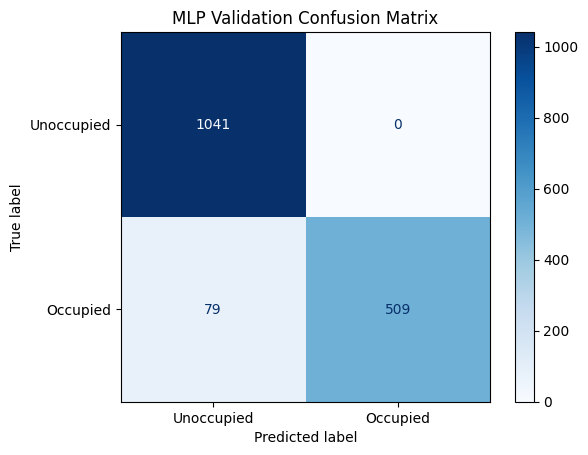

[[1041    0]
 [  79  509]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Unoccupied", "Occupied"]
)

disp.plot(cmap="Blues")
plt.title("MLP Validation Confusion Matrix")
plt.show()

print(cm)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [ ]:
y_val_rf_pred = rf_model.predict(X_val)

rf_val_accuracy = accuracy_score(y_val, y_val_rf_pred)
rf_val_precision = precision_score(y_val, y_val_rf_pred, zero_division=0)
rf_val_recall = recall_score(y_val, y_val_rf_pred, zero_division=0)
rf_val_f1 = f1_score(y_val, y_val_rf_pred, zero_division=0)

print("Random Forest Validation Results")
print("Accuracy:", round(rf_val_accuracy, 4))
print("Precision:", round(rf_val_precision, 4))
print("Recall:", round(rf_val_recall, 4))
print("F1-score:", round(rf_val_f1, 4))

Random Forest Validation Results
Accuracy: 0.9951
Precision: 0.9966
Recall: 0.9898
F1-score: 0.9932


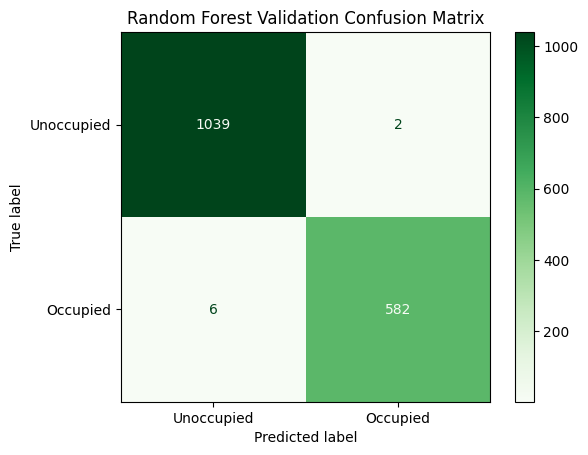

[[1039    2]
 [   6  582]]


In [ ]:
cm_rf = confusion_matrix(y_val, y_val_rf_pred)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Unoccupied", "Occupied"]
)

disp_rf.plot(cmap="Greens")
plt.title("Random Forest Validation Confusion Matrix")
plt.show()

print(cm_rf)

In [ ]:
thresholds = [0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    y_pred = (y_val_pred_prob >= threshold).astype(int).ravel()

    print("Threshold:", threshold)
    print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
    print("Precision:", round(precision_score(y_val, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_val, y_pred, zero_division=0), 4))
    print("F1-score:", round(f1_score(y_val, y_pred, zero_division=0), 4))
    print("-------------------------")

Threshold: 0.2
Accuracy: 0.9638
Precision: 0.9944
Recall: 0.9048
F1-score: 0.9475
-------------------------
Threshold: 0.3
Accuracy: 0.9638
Precision: 0.9944
Recall: 0.9048
F1-score: 0.9475
-------------------------
Threshold: 0.4
Accuracy: 0.9576
Precision: 1.0
Recall: 0.8827
F1-score: 0.9377
-------------------------
Threshold: 0.5
Accuracy: 0.9515
Precision: 1.0
Recall: 0.8656
F1-score: 0.928
-------------------------


In [ ]:
BEST_THRESHOLD = 0.3

y_val_mlp_tuned = (
    y_val_pred_prob >= BEST_THRESHOLD
).astype(int).ravel()

print("Selected Threshold:", BEST_THRESHOLD)
print("Accuracy:", accuracy_score(y_val, y_val_mlp_tuned))
print("Precision:", precision_score(y_val, y_val_mlp_tuned))
print("Recall:", recall_score(y_val, y_val_mlp_tuned))
print("F1-score:", f1_score(y_val, y_val_mlp_tuned))

Selected Threshold: 0.3
Accuracy: 0.9637814610190301
Precision: 0.994392523364486
Recall: 0.9047619047619048
F1-score: 0.9474621549421193


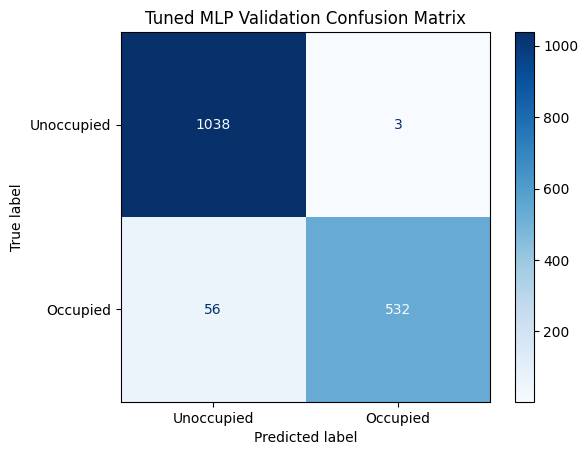

[[1038    3]
 [  56  532]]


In [ ]:
cm_tuned = confusion_matrix(y_val, y_val_mlp_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Unoccupied", "Occupied"]
)

disp.plot(cmap="Blues")
plt.title("Tuned MLP Validation Confusion Matrix")
plt.show()

print(cm_tuned)

In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(model_name, y_true, y_pred):
    print(f"\n{model_name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

BEST_THRESHOLD = 0.3

y_test1_mlp_prob = mlp_model.predict(X_test1)
y_test1_mlp_pred = (y_test1_mlp_prob >= BEST_THRESHOLD).astype(int).ravel()

y_test2_mlp_prob = mlp_model.predict(X_test2)
y_test2_mlp_pred = (y_test2_mlp_prob >= BEST_THRESHOLD).astype(int).ravel()

y_test1_rf_pred = rf_model.predict(X_test1)
y_test2_rf_pred = rf_model.predict(X_test2)

evaluate_model("MLP - Test 1", y_test1, y_test1_mlp_pred)
evaluate_model("Random Forest - Test 1", y_test1, y_test1_rf_pred)

evaluate_model("MLP - Test 2", y_test2, y_test2_mlp_pred)
evaluate_model("Random Forest - Test 2", y_test2, y_test2_rf_pred)


84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
305/305 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

MLP - Test 1
Accuracy: 0.9707317073170731
Precision: 0.9265267175572519
Recall: 0.9989711934156379
F1-score: 0.9613861386138614
Confusion Matrix:
[[1616   77]
 [   1  971]]

Random Forest - Test 1
Accuracy: 0.926078799249531
Precision: 0.9408418657565415
Recall: 0.8508230452674898
F1-score: 0.8935710426796326
Confusion Matrix:
[[1641   52]
 [ 145  827]]

MLP - Test 2
Accuracy: 0.9128383921246924
Precision: 0.7252912438932732
Recall: 0.9419228892142508
F1-score: 0.8195329087048833
Confusion Matrix:
[[6972  731]
 [ 119 1930]]

Random Forest - Test 2
Accuracy: 0.9687243642329778
Precision: 0.9448979591836735
Recall: 0.9038555392874573
F1-score: 0.9239211773509604
Confusion Matrix:
[[7595  108]
 [ 197 1852]]
